# CART Regression Using Python
## Predicting Yacht Hydrodynamic Resistance

### 1. Introduction

Decision Trees are supervised machine learning algorithms that can be used for both classification and regression tasks. They divide a dataset into smaller groups using a series of decision rules.

In this assignment, I am implementing the Classification and Regression Tree (CART) algorithm using the Yacht Hydrodynamics dataset.

The main purpose of this project is to estimate the hydrodynamic resistance of sailing yachts using their hull characteristics and speed-related measurements.

Since the target variable contains continuous numerical values, I have selected CART Regression instead of classification.

### 2. Objectives

- Understand and explore the selected dataset.
- Identify the input features and target variable.
- Perform an 80:20 train-test split.
- Understand regression impurity using Mean Squared Error.
- Implement CART using DecisionTreeRegressor.
- Evaluate the model using regression metrics.
- Visualize the decision tree and feature importance.
- Predict resistance for a new yacht observation.

I am importing the necessary Python libraries for handling the dataset, performing mathematical operations, creating visualizations, splitting the data and implementing the CART regression algorithm.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
#from ucimlrepo import fetch_ucirepo

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeRegressor, plot_tree, export_text

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

I selected the Yacht Hydrodynamics dataset from the UCI Machine Learning Repository. It contains different measurements related to yacht design and speed, which can help estimate its hydrodynamic resistance.

In [28]:
project_dir = Path.cwd()

if project_dir.name == "notebooks":
    project_dir = project_dir.parent

data_dir = project_dir / "data"
images_dir = project_dir / "images"

data_dir.mkdir(exist_ok=True)
images_dir.mkdir(exist_ok=True)

df = pd.read_csv(
    data_dir / "yacht_hydrodynamics.data",
    sep=r"\s+",
    header=None
)

df.columns = [
    "center_of_buoyancy",
    "prismatic_coefficient",
    "length_displacement_ratio",
    "beam_draught_ratio",
    "length_beam_ratio",
    "froude_number",
    "residuary_resistance"
]

df.to_csv(data_dir / "yacht_hydrodynamics.csv", index=False)

df.head()

,center_of_buoyancy,prismatic_coefficient,length_displacement_ratio,beam_draught_ratio,length_beam_ratio,froude_number,residuary_resistance
0,-2.3,0.568,4.78,3.99,3.17,0.125,0.11
1,-2.3,0.568,4.78,3.99,3.17,0.150,0.27
2,-2.3,0.568,4.78,3.99,3.17,0.175,0.47
3,-2.3,0.568,4.78,3.99,3.17,0.200,0.78
4,-2.3,0.568,4.78,3.99,3.17,0.225,1.18


Before training the model, I want to understand the dataset's structure and the type of information available. This includes checking the number of records, feature names, data types and statistical values.

In [29]:
print("Dataset Shape:", df.shape)

print("\nFirst Five Records:")
display(df.head())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())
plt.savefig(images_dir / "actual_vs_predicted.png", dpi=300)

Dataset Shape: (308, 7)

First Five Records:


,center_of_buoyancy,prismatic_coefficient,length_displacement_ratio,beam_draught_ratio,length_beam_ratio,froude_number,residuary_resistance
0,-2.3,0.568,4.78,3.99,3.17,0.125,0.11
1,-2.3,0.568,4.78,3.99,3.17,0.150,0.27
2,-2.3,0.568,4.78,3.99,3.17,0.175,0.47
3,-2.3,0.568,4.78,3.99,3.17,0.200,0.78
4,-2.3,0.568,4.78,3.99,3.17,0.225,1.18



Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 308 entries, 0 to 307
Data columns (total 7 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   center_of_buoyancy         308 non-null    float64
 1   prismatic_coefficient      308 non-null    float64
 2   length_displacement_ratio  308 non-null    float64
 3   beam_draught_ratio         308 non-null    float64
 4   length_beam_ratio          308 non-null    float64
 5   froude_number              308 non-null    float64
 6   residuary_resistance       308 non-null    float64
dtypes: float64(7)
memory usage: 17.0 KB

Statistical Summary:


,center_of_buoyancy,prismatic_coefficient,length_displacement_ratio,beam_draught_ratio,length_beam_ratio,froude_number,residuary_resistance
count,308.000000,308.000000,308.000000,308.000000,308.000000,308.000000,308.000000
mean,-2.381818,0.564136,4.788636,3.936818,3.206818,0.287500,10.495357
std,1.513219,0.023290,0.253057,0.548193,0.247998,0.100942,15.160490
min,-5.000000,0.530000,4.340000,2.810000,2.730000,0.125000,0.010000
25%,-2.400000,0.546000,4.770000,3.750000,3.150000,0.200000,0.777500
50%,-2.300000,0.565000,4.780000,3.955000,3.150000,0.287500,3.065000
75%,-2.300000,0.574000,5.100000,4.170000,3.510000,0.375000,12.815000
max,0.000000,0.600000,5.140000,5.350000,3.640000,0.450000,62.420000


<Figure size 640x480 with 0 Axes>

In this step, I am checking for missing values, duplicate records and incorrect data types. This helps me understand whether the dataset needs additional preprocessing before model training.

In [30]:
print("Missing Values:")
print(df.isnull().sum())

print("\nTotal Missing Values:", df.isnull().sum().sum())

print("\nDuplicate Records:", df.duplicated().sum())

print("\nData Types:")
print(df.dtypes)
plt.savefig(images_dir / "cart_decision_tree.png", dpi=300)

Missing Values:
center_of_buoyancy           0
prismatic_coefficient        0
length_displacement_ratio    0
beam_draught_ratio           0
length_beam_ratio            0
froude_number                0
residuary_resistance         0
dtype: int64

Total Missing Values: 0

Duplicate Records: 0

Data Types:
center_of_buoyancy           float64
prismatic_coefficient        float64
length_displacement_ratio    float64
beam_draught_ratio           float64
length_beam_ratio            float64
froude_number                float64
residuary_resistance         float64
dtype: object


<Figure size 640x480 with 0 Axes>

The six yacht measurements are used as independent variables, while residuary resistance is the dependent variable that the model needs to predict.

In [14]:
X = df.drop("residuary_resistance", axis=1)
y = df["residuary_resistance"]

print("Input Features:")
print(X.columns.tolist())

print("\nTarget Variable:")
print(y.name)

print("\nNumber of Input Features:", X.shape[1])
print("Number of Target Values:", len(y))

Input Features:
['center_of_buoyancy', 'prismatic_coefficient', 'length_displacement_ratio', 'beam_draught_ratio', 'length_beam_ratio', 'froude_number']

Target Variable:
residuary_resistance

Number of Input Features: 6
Number of Target Values: 308


I am plotting the distribution of the target variable to understand how the resistance values are spread across the dataset. This gives an initial idea about the numerical values the model will predict.

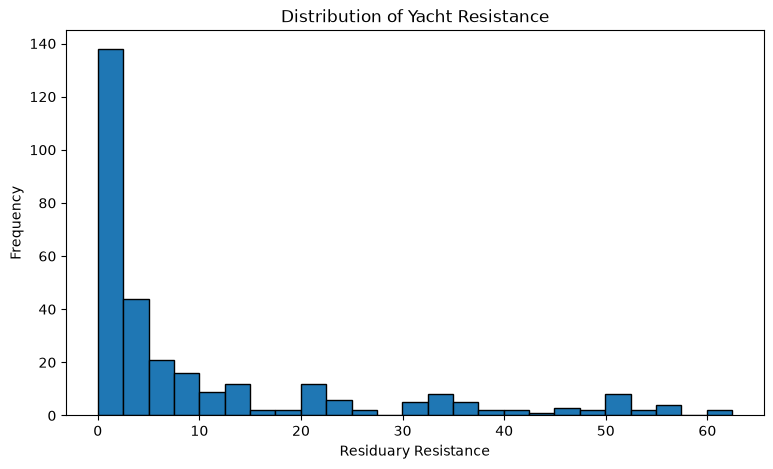

<Figure size 640x480 with 0 Axes>

In [31]:
plt.figure(figsize=(9, 5))

plt.hist(y, bins=25, edgecolor="black")

plt.xlabel("Residuary Resistance")
plt.ylabel("Frequency")
plt.title("Distribution of Yacht Resistance")

plt.show()
plt.savefig(images_dir / "feature_importance.png", dpi=300)

I am dividing the dataset into training and testing sets. The training data will be used to build the decision tree, while the testing data will be used to check how well the model performs on unseen observations.

In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))

Training Records: 246
Testing Records: 62


In CART Regression, the algorithm measures impurity using the variation of numerical target values within a node. Mean Squared Error is used to measure how far the observations are from their mean value.

A good split reduces the weighted impurity of the child nodes compared with the parent node.

In [17]:
parent_mean = y_train.mean()

parent_mse = np.mean(
    (y_train - parent_mean) ** 2
)

print("Parent Mean:", round(parent_mean, 4))
print("Parent MSE:", round(parent_mse, 4))

Parent Mean: 11.3638
Parent MSE: 245.6382


A decision tree that grows too deep may learn unnecessary details from the training data. To understand this, I am comparing multiple tree depths using five-fold cross-validation on the training data.

This helps identify a suitable tree complexity without using the test set for model selection.

In [18]:
depth_values = [2, 3, 4, 5, None]

depth_results = []

for depth in depth_values:

    model = DecisionTreeRegressor(
        criterion="squared_error",
        max_depth=depth,
        min_samples_leaf=3,
        random_state=42
    )

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=5,
        scoring="neg_root_mean_squared_error"
    )

    depth_results.append({
        "Max Depth": str(depth),
        "Mean CV RMSE": -scores.mean()
    })

depth_df = pd.DataFrame(depth_results)

display(depth_df.sort_values("Mean CV RMSE"))

,Max Depth,Mean CV RMSE
4,None,1.306628
3,5,1.363903
2,4,1.435206
1,3,1.688469
0,2,3.506769


After comparing the tree depths, I am selecting the depth with the lowest average cross-validation RMSE. I am using DecisionTreeRegressor with the squared error criterion to implement CART Regression.

The model uses binary splits to divide the observations into smaller groups and predicts a numerical value at each leaf node.

In [19]:
best_depth = depth_df.loc[
    depth_df["Mean CV RMSE"].idxmin(),
    "Max Depth"
]

best_depth = None if best_depth == "None" else int(best_depth)

cart_model = DecisionTreeRegressor(
    criterion="squared_error",
    splitter="best",
    max_depth=best_depth,
    min_samples_leaf=3,
    random_state=42
)

cart_model.fit(X_train, y_train)

print("CART Regression Model Trained Successfully!")
print("Selected Maximum Depth:", best_depth)
print("Actual Tree Depth:", cart_model.get_depth())
print("Number of Leaves:", cart_model.get_n_leaves())

CART Regression Model Trained Successfully!
Selected Maximum Depth: None
Actual Tree Depth: 10
Number of Leaves: 69


After training the model, I am using it to predict resistance values for the test dataset. I am comparing actual and predicted values to understand the model's performance.

In [20]:
y_pred = cart_model.predict(X_test)

results = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})

display(results.head(15))

,Actual,Predicted
0,6.31,6.446667
1,7.16,7.942000
2,0.35,0.283333
3,1.37,1.040000
4,21.09,21.216667
5,3.99,4.110000
6,5.82,5.137500
7,0.46,0.646667
8,2.84,2.880000
9,1.37,1.206000


I am evaluating the model using MAE, MSE, RMSE and R². These metrics help measure the difference between actual and predicted resistance values and indicate how well the model explains the variation in the target variable.

In [21]:
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("Model Evaluation Results")

print("MAE:", round(mae, 4))
print("MSE:", round(mse, 4))
print("RMSE:", round(rmse, 4))
print("R2 Score:", round(r2, 4))

Model Evaluation Results
MAE: 0.3972
MSE: 0.7022
RMSE: 0.838
R2 Score: 0.9953


I am plotting the actual resistance values against the predicted values. If the predictions are accurate, most of the points should appear close to the diagonal reference line.

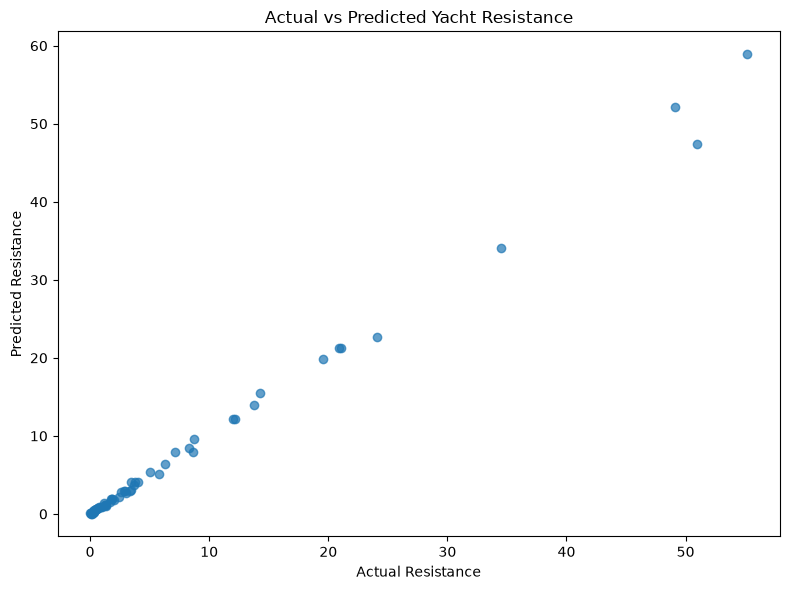

In [23]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.7)

plt.xlabel("Actual Resistance")
plt.ylabel("Predicted Resistance")
plt.title("Actual vs Predicted Yacht Resistance")

plt.tight_layout()
plt.savefig(images_dir / "actual_vs_predicted.png", dpi=300)
plt.show()

Feature importance helps identify which input variables contributed most to the decision tree's splitting process. I am arranging the features according to their importance to understand which yacht characteristics were most useful for prediction.

,Feature,Importance
5,froude_number,0.990357
1,prismatic_coefficient,0.007802
0,center_of_buoyancy,0.001400
3,beam_draught_ratio,0.000437
4,length_beam_ratio,0.000003
2,length_displacement_ratio,0.000001


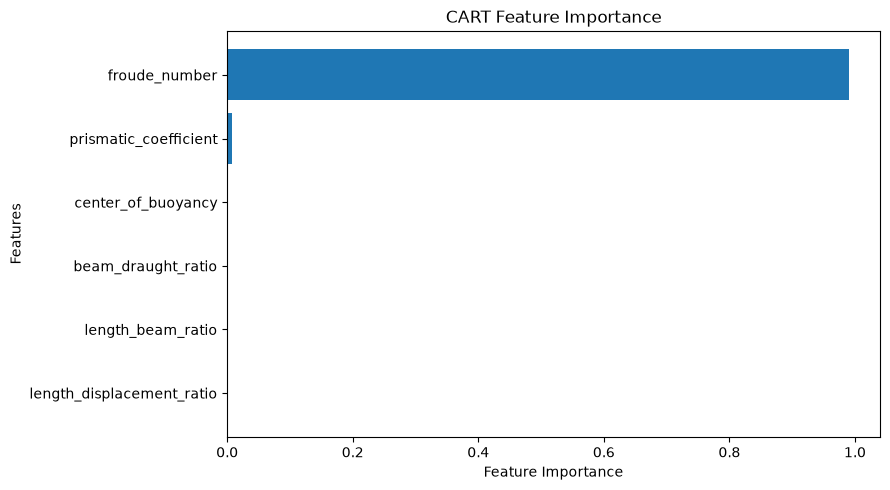

In [25]:
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": cart_model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

display(importance)

plt.figure(figsize=(9, 5))

plt.barh(
    importance["Feature"],
    importance["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("CART Feature Importance")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.savefig(images_dir / "feature_importance.png", dpi=300)
plt.show()

One advantage of decision trees is that their decisions can be represented as understandable rules. I am extracting the rules from the trained tree to see how different feature conditions lead to resistance predictions.

In [26]:
tree_rules = export_text(
    cart_model,
    feature_names=list(X.columns),
    max_depth=4
)

print(tree_rules)

|--- froude_number <= 0.39
|   |--- froude_number <= 0.34
|   |   |--- froude_number <= 0.26
|   |   |   |--- froude_number <= 0.21
|   |   |   |   |--- froude_number <= 0.16
|   |   |   |   |   |--- truncated branch of depth 6
|   |   |   |   |--- froude_number >  0.16
|   |   |   |   |   |--- truncated branch of depth 6
|   |   |   |--- froude_number >  0.21
|   |   |   |   |--- froude_number <= 0.24
|   |   |   |   |   |--- truncated branch of depth 5
|   |   |   |   |--- froude_number >  0.24
|   |   |   |   |   |--- truncated branch of depth 5
|   |   |--- froude_number >  0.26
|   |   |   |--- froude_number <= 0.31
|   |   |   |   |--- froude_number <= 0.29
|   |   |   |   |   |--- truncated branch of depth 5
|   |   |   |   |--- froude_number >  0.29
|   |   |   |   |   |--- truncated branch of depth 4
|   |   |   |--- froude_number >  0.31
|   |   |   |   |--- beam_draught_ratio <= 3.72
|   |   |   |   |   |--- value: [4.39]
|   |   |   |   |--- beam_draught_ratio >  3.72
|   |

Finally, I am testing the trained model using a new input observation. I am using the median values of the dataset's features to create an illustrative input that stays within the observed feature ranges.

In [27]:
new_yacht = pd.DataFrame(
    [X.median().values],
    columns=X.columns
)

prediction = cart_model.predict(new_yacht)

print("New Yacht Measurements:")
display(new_yacht)

print(
    "Predicted Residuary Resistance:",
    round(prediction[0], 4)
)

New Yacht Measurements:


,center_of_buoyancy,prismatic_coefficient,length_displacement_ratio,beam_draught_ratio,length_beam_ratio,froude_number
0,-2.3,0.565,4.78,3.955,3.15,0.2875


Predicted Residuary Resistance: 2.88


Use this conclusion after running the notebook. Replace the placeholders with your actual results.

# 3. Conclusion

In this assignment, I implemented CART Regression using the Yacht Hydrodynamics dataset to predict the residuary resistance of sailing yachts.

I explored the dataset, checked its quality, identified the input features and target variable, and divided the observations into training and testing sets.

I used Mean Squared Error as the regression impurity measure and implemented the CART algorithm using DecisionTreeRegressor. I also compared different tree depths through cross-validation to understand the effect of model complexity.

The model was evaluated using MAE, MSE, RMSE and R². The decision tree visualization and feature importance analysis helped me understand how the model makes predictions.

Overall, this assignment helped me understand how CART Regression works, how binary splits are selected, and how decision trees can be used to solve real-world numerical prediction problems.